# US Employment in AI, Data Science and Software Development

**Name:** Fredrick Kimutai 
**Student number:** 2024658 
**GitHub repository:** https://github.com/2024658/Data_Visualisation_CA1

## Project Introduction
This notebook explores the May 2023 Occupational Employment and Wage Statistics (OEWS) dataset from the US Bureau of Labor Statistics (BLS, 2023). The data is a snapshot of employment and wages by occupation, industry and location.

The purpose of the notebook is to use a range of visualisation types to show how large AI, data science and software occupations are, how well they are paid, and how this varies by place and over time. Each visualisation is explained so that we can see why that chart type fits the data.

For each of the visualisations, we explain:

1. The objective of the visualisation.
2. **Why that visualisation type was chosen** (categorical, numerical and relationship).
3. **What we have learnt** from the plot.

The BLS data has no single AI employment category, so we use eight related occupations in its place. These are:

- **AI & Data Science:** Data Scientists, Computer and Information Research Scientists, Operations Research Analysts and Statisticians
- **Software:** Software Developers and QA Analysts and Testers
- **Data Infrastructure:** Database Architects and Database Administrators

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# Load dataset
cols = ["AREA_TITLE", "AREA_TYPE", "I_GROUP", "OCC_CODE", "OCC_TITLE", "O_GROUP", "TOT_EMP", "A_MEDIAN"]
df = pd.read_excel("all_data_M_2023.xlsx", sheet_name="All May 2023 data", usecols=cols, na_values=["*", "**", "#", "~"])
df.head()

,AREA_TITLE,AREA_TYPE,I_GROUP,OCC_CODE,OCC_TITLE,O_GROUP,TOT_EMP,A_MEDIAN
0,U.S.,1,cross-industry,00-0000,All Occupations,total,151853870.0,48060.0
1,U.S.,1,cross-industry,11-0000,Management Occupations,major,10495770.0,116880.0
2,U.S.,1,cross-industry,11-1000,Top Executives,minor,3751510.0,103460.0
3,U.S.,1,cross-industry,11-1010,Chief Executives,broad,211230.0,206680.0
4,U.S.,1,cross-industry,11-1011,Chief Executives,detailed,211230.0,206680.0


In [3]:
groups = {"15-2051": "AI & Data Science", "15-1221": "AI & Data Science",
          "15-2041": "AI & Data Science", "15-2031": "AI & Data Science",
          "15-1252": "Software", "15-1253": "Software",
          "15-1243": "Data Infrastructure", "15-1242": "Data Infrastructure"}

# National totals : U.S. rows, all industries combined, one row per occupation
us = df[(df["AREA_TITLE"] == "U.S.") & (df["I_GROUP"] == "cross-industry")]
nat = us[(us["O_GROUP"] == "detailed") & (us["OCC_CODE"].isin(groups))].copy()
nat["group"] = nat["OCC_CODE"].map(groups)

# Benchmark: median salary of ALL US jobs
us_median = us[us["O_GROUP"] == "total"]["A_MEDIAN"].iloc[0]
print("Median salary of all US jobs:", us_median)
nat[["OCC_TITLE", "TOT_EMP", "A_MEDIAN", "group"]]

Median salary of all US jobs: 48060.0


,OCC_TITLE,TOT_EMP,A_MEDIAN,group
138,Computer and Information Research Scientists,35210.0,145080.0,AI & Data Science
144,Database Administrators,76140.0,101510.0,Data Infrastructure
145,Database Architects,59920.0,134700.0,Data Infrastructure
149,Software Developers,1656880.0,132270.0,Software
150,Software Quality Assurance Analysts and Testers,203040.0,101800.0,Software
161,Operations Research Analysts,117880.0,83640.0,AI & Data Science
163,Statisticians,29950.0,104110.0,AI & Data Science
165,Data Scientists,192710.0,108020.0,AI & Data Science


## 1. Horizontal Bar Chart - Employment by Occupation

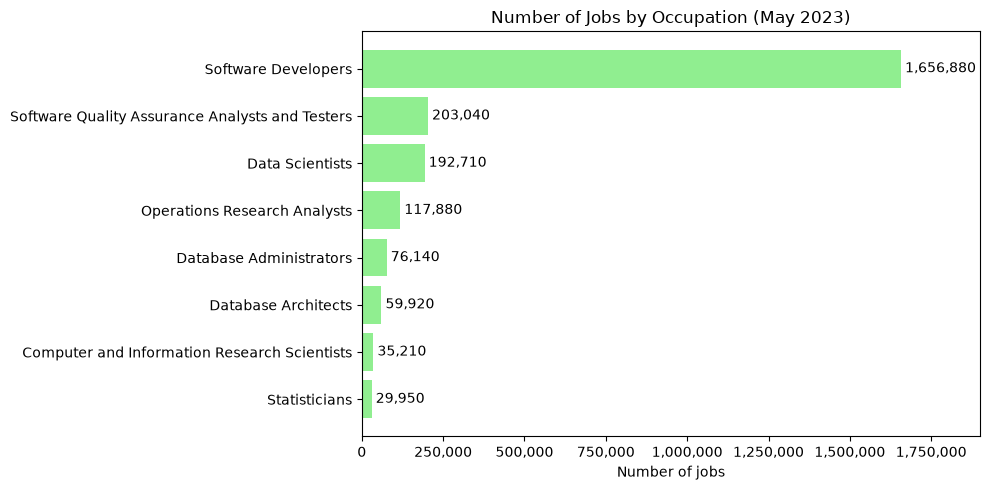

In [6]:
emp = nat.sort_values("TOT_EMP")

plt.figure(figsize=(10, 5))
bars = plt.barh(emp["OCC_TITLE"], emp["TOT_EMP"], color="lightgreen")
plt.bar_label(bars, fmt="{:,.0f}", padding=3)
plt.gca().xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
plt.xlim(0, 1_900_000)
plt.title("Number of Jobs by Occupation (May 2023)")
plt.xlabel("Number of jobs")
plt.tight_layout()
plt.show()

- **Objective:** To compare how many people work in each of our eight occupations, to see how big AI and data roles are next to software roles.
- **Why this plot:** Horizontal bars suit long category labels like occupation names, and sorting the bars shows the rank better.
- **Learning:** AI related jobs are less  compared with general software work. Software Developers dominate with about 1.66 million jobs, roughly eight times the next largest (QA Analysts and Testers, 203,040). Data Scientists have 192,710 jobs and Statisticians only 29,950.

## 2.Bar chart - Median Salary by Occupations

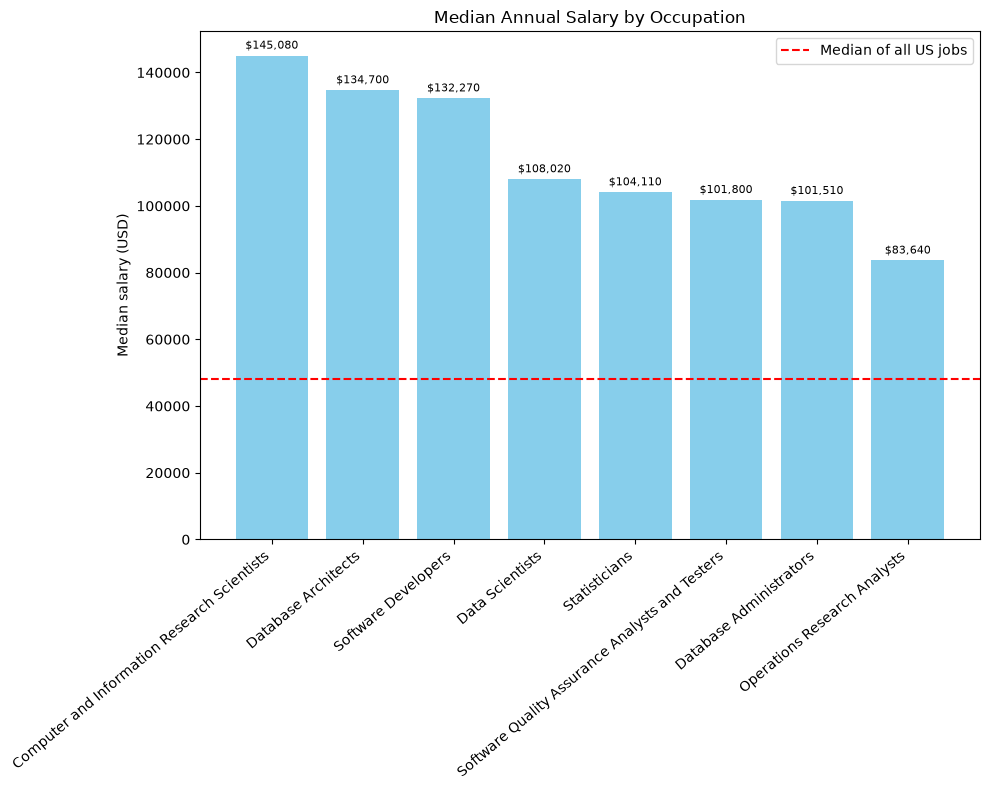

In [14]:
pay = nat.sort_values("A_MEDIAN", ascending=False)

plt.figure(figsize=(10, 8))
plt.bar(pay["OCC_TITLE"], pay["A_MEDIAN"], color="skyblue")
plt.axhline(us_median, color="red", linestyle="--", label="Median of all US jobs")
plt.xticks(rotation=40, ha="right")
plt.title("Median Annual Salary by Occupation")
plt.ylabel("Median salary (USD)")
plt.bar_label(bars, fmt="${:,.0f}", padding=3, fontsize=8)
plt.legend()
plt.tight_layout()
plt.show()

- **Objective:** Compare typical pay across the eight occupations and against the normal US worker.
- **Why this plot:** Bar charts compare one numeric value across a small number of categories, and the dashed line adds a benchmark for context.
- **Learning:** Computer and Information Research Scientists earn the most, about three times the US median of $48,060 and Operations Research Analysts the least. and Data Scientists earn less than Software Developers.

## 3. Pie Chart – Share of Jobs by Role Group

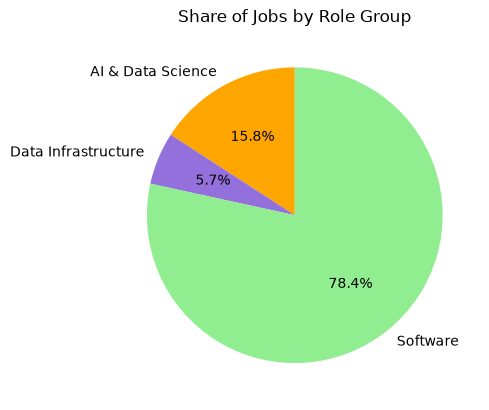

In [17]:
share = nat.groupby("group")["TOT_EMP"].sum()

plt.pie(share, labels=share.index, autopct="%1.1f%%", startangle=90, colors=["orange", "mediumpurple", "lightgreen"])
plt.title("Share of Jobs by Role Group")
plt.show()

- **Objective:** Show how the jobs in the eight occupations divide between the three role groups.
- **Why this plot:** Pie charts are good for whole-part relationships when there are only a few slices that add up to 100%.
- **Learning:** Software makes a majority of these jobs at 78%, AI & Data Science  and Data Infrastructure follow at about 16% and 6% respectively .